# Midterm worked example · Regex model vs Gemini model

**OPIM 5512 · Dr. Wanik's own cars (467 Hartford-area listings, Sep 28 to Oct 14, 2026)**

This is how a data science team answers a question at work: write the question down, design a **fair test**, run it,
check whether the result is **real or luck**, then explain **why** the winner wins. You will do exactly this with your
own cars for the midterm (same notebook, your data).

**The question.** In A07 we taught Gemini to read every ad and return new fields (transmission, title status, body
type, ...). Gemini also re-reads price, year, make, model and mileage. **Does a price model built on Gemini's features
beat the Lab 4 model built on regex features?** And if it does, is that because Gemini reads the *same* fields better,
or because the *new* fields carry new information?

**The experiment.**

| | |
|---|---|
| **Control (v1)** | Lab 4's 4 regex features: year, mileage, make, model |
| **Treatment (v2)** | Gemini's 4 + the new A07 fields |
| **Ablation (v1.5)** | Gemini's 4 only: isolates "better reading" from "new fields" |
| **Same cars** | both tables joined on `post_id`; a car flagged in **either** table is dropped from **both** |
| **Same target** | the asking price |
| **Same calendar** | train on older cars, test on the newest cars (like production: the model always prices the future) |
| **Same recipe** | Lab 4's cleaning, flags, 3 model families and grids, seed, 5-fold CV |
| **Metric** | MAE in dollars (lower is better) |

Only one thing changes between versions: the feature list. That is what makes it an experiment.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import sklearn
from sklearn.model_selection import GridSearchCV, RepeatedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

SEED = 42
pd.set_option("display.max_columns", 30)

C:\Users\dww05002\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load both master tables
The regex table is what `materialize-master` builds every hour; the Gemini table is what A07's `materialize-llm`
builds. (The starter notebook reads both straight from your bucket.) Dr. Wanik's cars end Oct 14, so his calendar
is: **train through Oct 7, test Oct 8 to 14**. Yours: train through Oct 20, test Oct 21 to 28.

In [2]:
BASE = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-labs/master/Module3/A07_GenAI_ETL/DrWanik_example/"
regex_raw = pd.read_csv(BASE + "DrWanik_listings_master_REGEX_2026-10-14.csv", dtype={"post_id": str})
gemini_raw = pd.read_csv(BASE + "DrWanik_listings_master_GEMINI_2026-10-14.csv", dtype={"post_id": str})

TRAIN_THROUGH = "2026-10-07"
TEST_FROM = "2026-10-08"
TEST_THROUGH = "2026-10-14"

print("regex table: ", regex_raw.shape)
print("gemini table:", gemini_raw.shape)

regex table:  (467, 9)
gemini table: (467, 19)


## 1b. Find the new Gemini columns, clean both tables the same way, join on `post_id`
Any column in the Gemini table that the regex table does not have is one of **your A07 fields**. They get the same
text cleaning as make and model (lowercase, blanks become missing). Inside the model, a missing new field becomes the
word `unknown` ("the ad did not say" is information too).

In [3]:
STANDARD = ["post_id", "run_id", "scraped_at", "price", "year", "make", "model", "mileage", "source_txt"]
NEW_FIELDS = []
for col in gemini_raw.columns:
    if col not in STANDARD:
        NEW_FIELDS.append(col)
print(len(NEW_FIELDS), "new Gemini fields:", NEW_FIELDS)
if len(NEW_FIELDS) == 0:
    print("No new Gemini columns found: check A07 Step 2, Edit 3 (out_record), then re-read your cars (A07 Step 4).")

NICKNAMES = {"chevy": "chevrolet", "vw": "volkswagen", "mercedes": "mercedes-benz", "benz": "mercedes-benz"}


def clean_cars(df, text_cols):
    """Lab 4's cleaning (the same steps predict-shap runs in production)."""
    out = df.copy()
    for col in ["price", "year", "mileage"]:
        out[col] = pd.to_numeric(out[col].astype(str).str.replace(r"[^\d.]+", "", regex=True), errors="coerce")
    for col in text_cols:
        out[col] = out[col].astype(str).str.strip().str.lower()
        out.loc[out[col].isin(["", "nan", "none", "<na>"]), col] = np.nan
    out["make"] = out["make"].replace(NICKNAMES)
    return out


regex_cars = clean_cars(regex_raw, ["make", "model"])
gemini_cars = clean_cars(gemini_raw, ["make", "model"] + NEW_FIELDS)
both = regex_cars.merge(gemini_cars.drop(columns=["scraped_at"]), on="post_id", suffixes=("_rx", "_gm"))
both["day"] = pd.to_datetime(both["scraped_at"], utc=True).dt.tz_convert("America/New_York").dt.strftime("%Y-%m-%d")
print(len(both), "cars are in both tables")

10 new Gemini fields: ['trim', 'body_type', 'drivetrain', 'transmission', 'fuel_type', 'exterior_color', 'title_status', 'condition', 'leather_seats', 'city']
467 cars are in both tables


### How often do the regex and Gemini agree?
Before modeling, look at the inputs. Where the two extractors disagree is exactly where the models can differ.

In [4]:
agree = {}
for col in ["price", "year", "mileage", "make", "model"]:
    agree[col] = (both[col + "_rx"] == both[col + "_gm"]).mean()
print(pd.Series(agree).round(3).to_string())
print()
print("Some cars where the MODEL disagrees:")
disagree = both[both["model_rx"] != both["model_gm"]]
disagree[["year_rx", "make_rx", "model_rx", "make_gm", "model_gm"]].head(10)

price      0.998
year       0.989
mileage    0.968
make       0.959
model      0.758

Some cars where the MODEL disagrees:


,year_rx,make_rx,model_rx,make_gm,model_gm
5,1997,dodge,ram,dodge,ram 1500
17,1968,pontiac,vin,pontiac,tempest
18,2016,bmw,3,bmw,320i xdrive
44,2008,audi,a4,audi,a4 quattro
46,2016,freightliner,business,freightliner,business class m2 106
56,2006,NaN,NaN,saab,9-5
57,2003,gmc,sierra,gmc,sierra 2500hd
58,1980,chevrolet,c10,chevrolet,k10 pickup
66,2011,aston,martin,aston martin,vantage s
67,1958,ford,fairlane,ford,fairlane 500


## 2. Flag junk rows once, for both versions
Lab 4's `review_reasons` rules. A car flagged in **either** table is dropped from **both**, so both models learn from
and are scored on exactly the same cars.

In [5]:
MIN_PRICE = 500
MAX_PRICE = 100000
PLACEHOLDER_MILES = [0, 99999, 999999]
OLDEST_YEAR = 1950


def is_flagged(price, year, mileage):
    bad_price = price.isna() | (price < MIN_PRICE) | (price > MAX_PRICE)
    bad_miles = mileage.isin(PLACEHOLDER_MILES)
    bad_year = year.isna() | (year < OLDEST_YEAR)
    return bad_price | bad_miles | bad_year


flag_rx = is_flagged(both["price_rx"], both["year_rx"], both["mileage_rx"])
flag_gm = is_flagged(both["price_gm"], both["year_gm"], both["mileage_gm"])
cars = both[~(flag_rx | flag_gm)].reset_index(drop=True)
print(int((flag_rx | flag_gm).sum()), "flagged,", len(cars), "cars in the experiment")

6 flagged, 461 cars in the experiment


## 3. Three feature tables, one target, one calendar split
Each version gets the same column names (`year`, `mileage`, `make`, `model`), so plots line up side by side.

In [6]:
CORE = ["year", "mileage", "make", "model"]
V1 = "v1 regex (4)"
V15 = "v1.5 gemini (4)"
V2 = "v2 gemini (" + str(4 + len(NEW_FIELDS)) + ")"

X_v1 = pd.DataFrame()                                  # v1: the regex reading
X_v1_5 = pd.DataFrame()                                # v1.5: Gemini's reading of the same 4 fields
for col in CORE:
    X_v1[col] = cars[col + "_rx"]
    X_v1_5[col] = cars[col + "_gm"]
for X in [X_v1, X_v1_5]:
    X["year"] = X["year"].astype(float)                # decimals, so partial dependence can try in-between years
    X["mileage"] = X["mileage"].astype(float)
X_v2 = X_v1_5.copy()                                   # v2: Gemini's 4 + the new fields
for col in NEW_FIELDS:
    X_v2[col] = cars[col]
VERSIONS = {V1: X_v1, V15: X_v1_5, V2: X_v2}

y = cars["price_rx"]                                   # the target: the asking price

train_idx = cars.index[cars["day"] <= TRAIN_THROUGH]
test_idx = cars.index[(cars["day"] >= TEST_FROM) & (cars["day"] <= TEST_THROUGH)]
print(len(train_idx), "training cars (through", TRAIN_THROUGH + ")")
print(len(test_idx), "test cars (" + TEST_FROM, "to", TEST_THROUGH + "), the same cars for every version")
X_v2.head(3)

374 training cars (through 2026-10-07)
87 test cars (2026-10-08 to 2026-10-14), the same cars for every version


,year,mileage,make,model,trim,body_type,drivetrain,transmission,fuel_type,exterior_color,title_status,condition,leather_seats,city
0,2020.0,170000.0,honda,hr-v,sport,suv,fwd,automatic,gas,gray,clean,good,false,plaiville
1,1966.0,84000.0,chevrolet,c10,NaN,truck,rwd,manual,gas,NaN,clean,good,NaN,NaN
2,2004.0,21000.0,pontiac,sunfire,NaN,coupe,fwd,automatic,gas,red,clean,like new,NaN,bolton


## 4. Tune all three model families for each version
Same `make_pipe` recipe as Lab 4, plus one line for v2: the new text columns are one-hot encoded too, with a blank
filled as `unknown`. Same grids. `train_cv_mae` = 5-fold CV MAE on the training cars; the champion is the lowest.

In [7]:
def make_pipe(estimator, features):
    numeric = Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    make_model = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                           ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=2))])
    new_text = Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                         ("oh", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=2))])
    parts = [("num", numeric, ["year", "mileage"]), ("cat", make_model, ["make", "model"])]
    new_cols = []
    for col in features:
        if col not in CORE:
            new_cols.append(col)
    if len(new_cols) > 0:
        parts.append(("new", new_text, new_cols))
    return Pipeline([("pre", ColumnTransformer(parts)), ("model", estimator)])


GRIDS = {
    "decision_tree": (DecisionTreeRegressor(random_state=SEED),
                      {"model__max_depth": [3, 5, 8, 12, None], "model__min_samples_leaf": [1, 5, 10, 20]}),
    "random_forest": (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                      {"model__n_estimators": [100, 300], "model__max_depth": [None, 10],
                       "model__min_samples_leaf": [1, 3, 5]}),
    "knn": (KNeighborsRegressor(),
            {"model__n_neighbors": [3, 5, 7, 11, 15], "model__weights": ["uniform", "distance"]}),
}

results = []
best = {}                                              # best[version] = the champion pipeline, refit on training cars
for version, X in VERSIONS.items():
    champ_mae = None
    for family, (estimator, grid) in GRIDS.items():
        search = GridSearchCV(make_pipe(estimator, list(X.columns)), grid, cv=5,
                              scoring="neg_mean_absolute_error", n_jobs=-1)
        search.fit(X.loc[train_idx], y.loc[train_idx])
        i = search.best_index_
        cv_mae = -search.cv_results_["mean_test_score"][i]
        test_mae = mean_absolute_error(y.loc[test_idx], search.predict(X.loc[test_idx]))
        results.append({"version": version, "family": family, "train_cv_mae": round(cv_mae),
                        "cv_std": round(search.cv_results_["std_test_score"][i]), "test_mae": round(test_mae)})
        if champ_mae is None or cv_mae < champ_mae:
            champ_mae = cv_mae
            best[version] = search.best_estimator_

median_guess = mean_absolute_error(y.loc[test_idx], np.full(len(test_idx), y.loc[train_idx].median()))
print("Baseline (guess the training median price): test MAE =", round(median_guess))
results = pd.DataFrame(results)
results.pivot(index="family", columns="version", values="train_cv_mae")

Baseline (guess the training median price): test MAE = 3812


version,v1 regex (4),v1.5 gemini (4),v2 gemini (14)
family,,,
decision_tree,3840,3727,3958
knn,3464,3486,3474
random_forest,3217,3308,3253


In [8]:
results.sort_values(["version", "train_cv_mae"])

,version,family,train_cv_mae,cv_std,test_mae
1,v1 regex (4),random_forest,3217,452,2394
2,v1 regex (4),knn,3464,512,2232
0,v1 regex (4),decision_tree,3840,906,2936
4,v1.5 gemini (4),random_forest,3308,392,2467
5,v1.5 gemini (4),knn,3486,471,2147
3,v1.5 gemini (4),decision_tree,3727,772,2302
7,v2 gemini (14),random_forest,3253,478,2246
8,v2 gemini (14),knn,3474,475,2591
6,v2 gemini (14),decision_tree,3958,956,2320


## 5. Is the difference real, or luck?
One test window of a few dozen cars is noisy: a few odd cars can swing the test MAE by hundreds of dollars. So we
re-run each version's **champion recipe** on **25 different splits** of all the cars (5-fold CV, repeated 5 times) and
compare versions **on the same folds** (a *paired* comparison). If v2 wins on almost every fold, the win is real.

In [9]:
folds = RepeatedKFold(n_splits=5, n_repeats=5, random_state=SEED)
fold_mae = pd.DataFrame()
for version, X in VERSIONS.items():
    scores = cross_val_score(best[version], X, y, cv=folds, scoring="neg_mean_absolute_error", n_jobs=-1)
    fold_mae[version] = -scores

diff = fold_mae[V1] - fold_mae[V2]                     # positive = Gemini better on that fold
half_width = 1.96 * diff.std() / np.sqrt(len(diff))
print(fold_mae.mean().round(0).to_string())
print()
print(V2, "beats", V1, "on", int((diff > 0).sum()), "of", len(diff), "folds")
print("Average improvement: $", round(diff.mean()), " (rough 95% interval: $", round(diff.mean() - half_width),
      " to $", round(diff.mean() + half_width), ")", sep="")

v1 regex (4)       3074.0
v1.5 gemini (4)    3174.0
v2 gemini (14)     2923.0

v2 gemini (14) beats v1 regex (4) on 21 of 25 folds
Average improvement: $150 (rough 95% interval: $66 to $234)


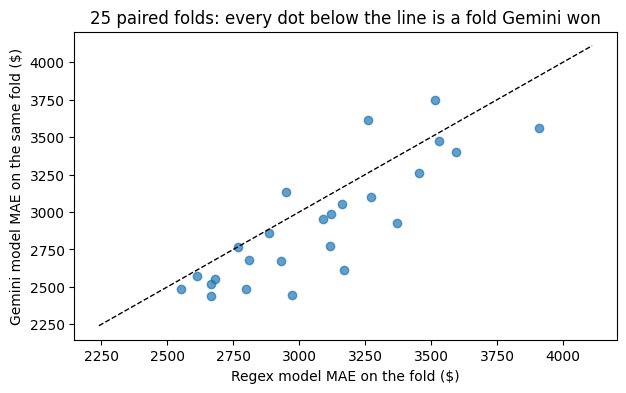

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(fold_mae[V1], fold_mae[V2], alpha=0.7)
low = fold_mae.min().min() - 200
high = fold_mae.max().max() + 200
ax.plot([low, high], [low, high], "k--", linewidth=1)
ax.set_xlabel("Regex model MAE on the fold ($)")
ax.set_ylabel("Gemini model MAE on the same fold ($)")
ax.set_title("25 paired folds: every dot below the line is a fold Gemini won")
plt.show()

**Read the ablation (v1.5).** Compare the three averages above:
- v1 regex (4) to **v1.5 gemini (4)**: same 4 fields, different reader. Any gain here is Gemini **reading better**.
- v1.5 to **v2**: same reader, more fields. Any gain here is the **new information** from A07.

## 6. Actual vs predicted, on the same newest cars
Points on the dashed line are perfect predictions. Look at where each model misses.

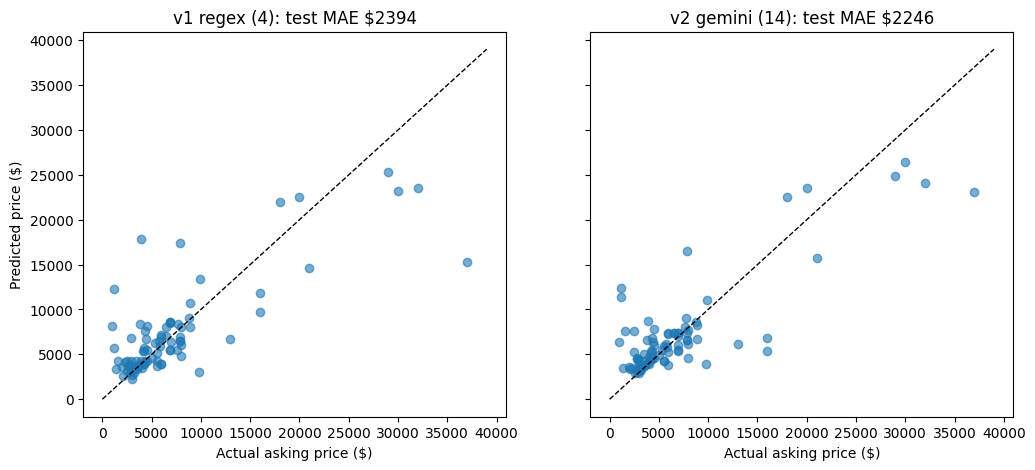

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
pairs = [(V1, axes[0]), (V2, axes[1])]
for version, ax in pairs:
    pred = best[version].predict(VERSIONS[version].loc[test_idx])
    mae = mean_absolute_error(y.loc[test_idx], pred)
    ax.scatter(y.loc[test_idx], pred, alpha=0.6)
    ax.plot([0, y.max()], [0, y.max()], "k--", linewidth=1)
    ax.set_title(version + ": test MAE $" + str(round(mae)))
    ax.set_xlabel("Actual asking price ($)")
axes[0].set_ylabel("Predicted price ($)")
plt.show()

## 7. Permutation importance: which inputs does each model actually rely on?
Shuffle one column on the test cars and measure how much worse the MAE gets. A big jump means the model leans on that
column. Each box is the 20 shuffles of one column, so you also see how stable the answer is (a box that crosses the
dashed zero line means "no clear effect"). It works the same way for any model, and it scores each **original** column
(all of `make`, not one-hot pieces).

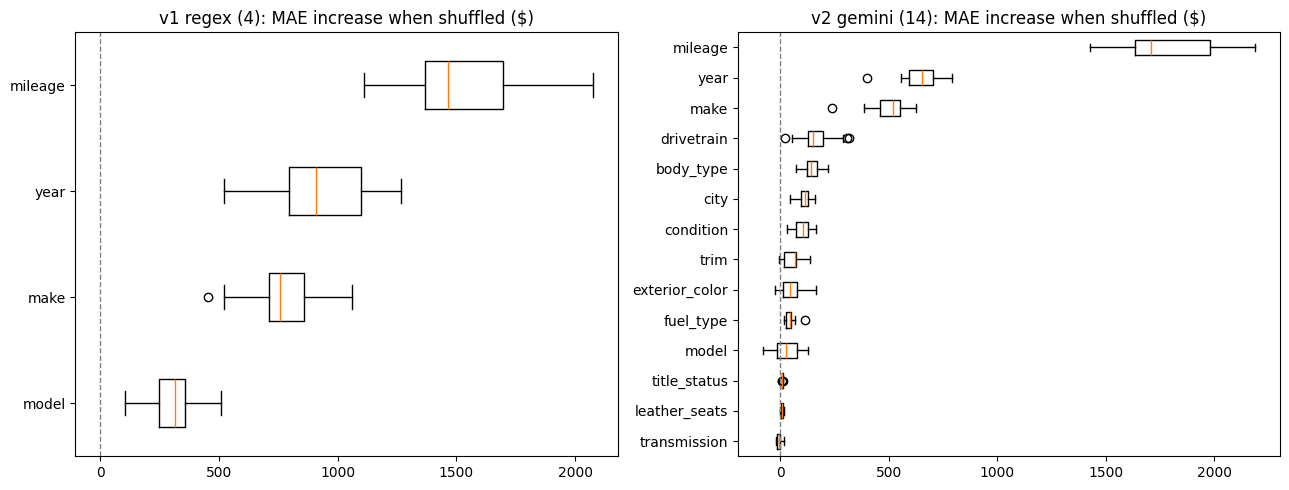

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pairs = [(V1, axes[0]), (V2, axes[1])]
for version, ax in pairs:
    X_test = VERSIONS[version].loc[test_idx]
    imp = permutation_importance(best[version], X_test, y.loc[test_idx], scoring="neg_mean_absolute_error",
                                 n_repeats=20, random_state=SEED, n_jobs=-1)
    order = np.argsort(imp.importances_mean)                      # least important at the bottom
    ax.boxplot(imp.importances[order].T, vert=False, tick_labels=X_test.columns[order])
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_title(version + ": MAE increase when shuffled ($)")
plt.tight_layout()
plt.show()

## 8. SHAP: the global picture for each model
SHAP splits every prediction into a push from each feature. We add the one-hot pieces back up so each original column
gets one SHAP value per car (the same trick `predict-shap` uses in production). **Bar** = average size of the push;
**beeswarm** = every car, colored by the feature's value (gray for text columns, which have no high/low).

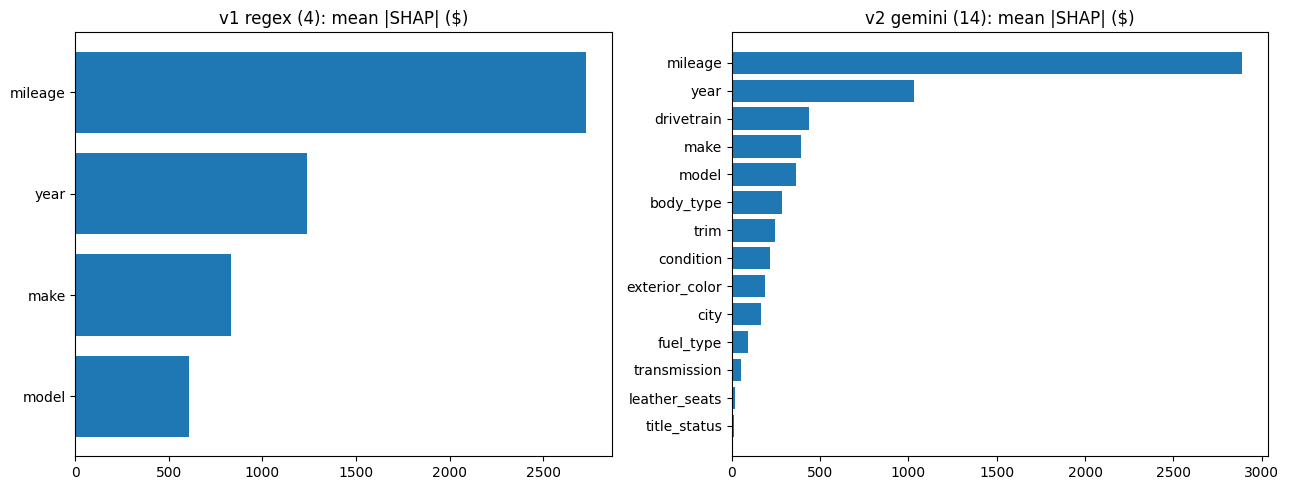

In [13]:
def grouped_shap(pipe, X):
    """One SHAP value per ORIGINAL column for every car in X (one-hot pieces added back together)."""
    pre = pipe.named_steps["pre"]
    model = pipe.named_steps["model"]
    Xt = pre.transform(X)
    if hasattr(Xt, "toarray"):
        Xt = Xt.toarray()
    if hasattr(model, "estimators_") or hasattr(model, "tree_"):
        explainer = shap.TreeExplainer(model)                  # exact and fast for trees
        values = explainer.shap_values(Xt, check_additivity=False)
    else:
        background = shap.kmeans(Xt, 10)                       # sampled estimate for KNN (slower)
        explainer = shap.KernelExplainer(model.predict, background)
        values = explainer.shap_values(Xt, nsamples=100, silent=True)
    names = list(pre.get_feature_names_out())
    grouped = pd.DataFrame(0.0, index=X.index, columns=list(X.columns))
    for j in range(len(names)):
        piece = names[j].split("__", 1)[1]                     # "cat__make_honda" -> "make_honda"
        owner = None
        for col in X.columns:                                  # the longest column name that starts the piece wins
            if piece == col or piece.startswith(col + "_"):
                if owner is None or len(col) > len(owner):
                    owner = col
        grouped[owner] += values[:, j]
    return grouped


shap_by_version = {}
for version in [V1, V2]:
    shap_by_version[version] = grouped_shap(best[version], VERSIONS[version].loc[test_idx])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
pairs = [(V1, axes[0]), (V2, axes[1])]
for version, ax in pairs:
    mean_abs = shap_by_version[version].abs().mean().sort_values()
    ax.barh(mean_abs.index, mean_abs.values)
    ax.set_title(version + ": mean |SHAP| ($)")
plt.tight_layout()
plt.show()

C:\Users\dww05002\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


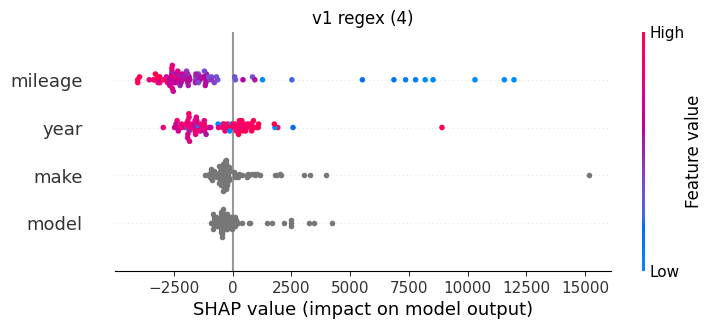

C:\Users\dww05002\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\lib\_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


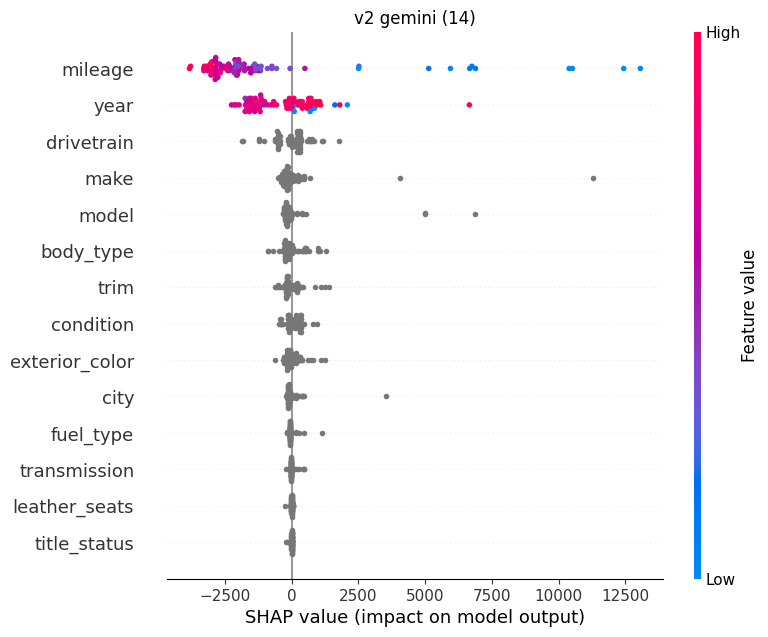

In [14]:
for version in [V1, V2]:
    X_test = VERSIONS[version].loc[test_idx]
    color_data = pd.DataFrame(np.nan, index=X_test.index, columns=X_test.columns)
    color_data["year"] = X_test["year"]
    color_data["mileage"] = X_test["mileage"]
    explanation = shap.Explanation(values=shap_by_version[version].values, data=color_data.values,
                                   feature_names=list(X_test.columns))
    shap.plots.beeswarm(explanation, max_display=20, show=False)
    plt.title(version)
    plt.show()

## 9. Partial dependence: how does the predicted price move with one input?
Hold everything else as it is, sweep one input, and average the predictions. Numbers first (year, mileage) for both
models: a line, one point per value tried. Then up to 4 of the new Gemini fields for v2 (change `new_to_show` to pick
yours). A text field has no "in between" values, so scikit-learn draws it as **one bar per value**: set *every*
training car to `manual`, predict them all, average; then do the same for `automatic`, and so on. Compare the bar
heights with each other (the y-axis does not start at zero).

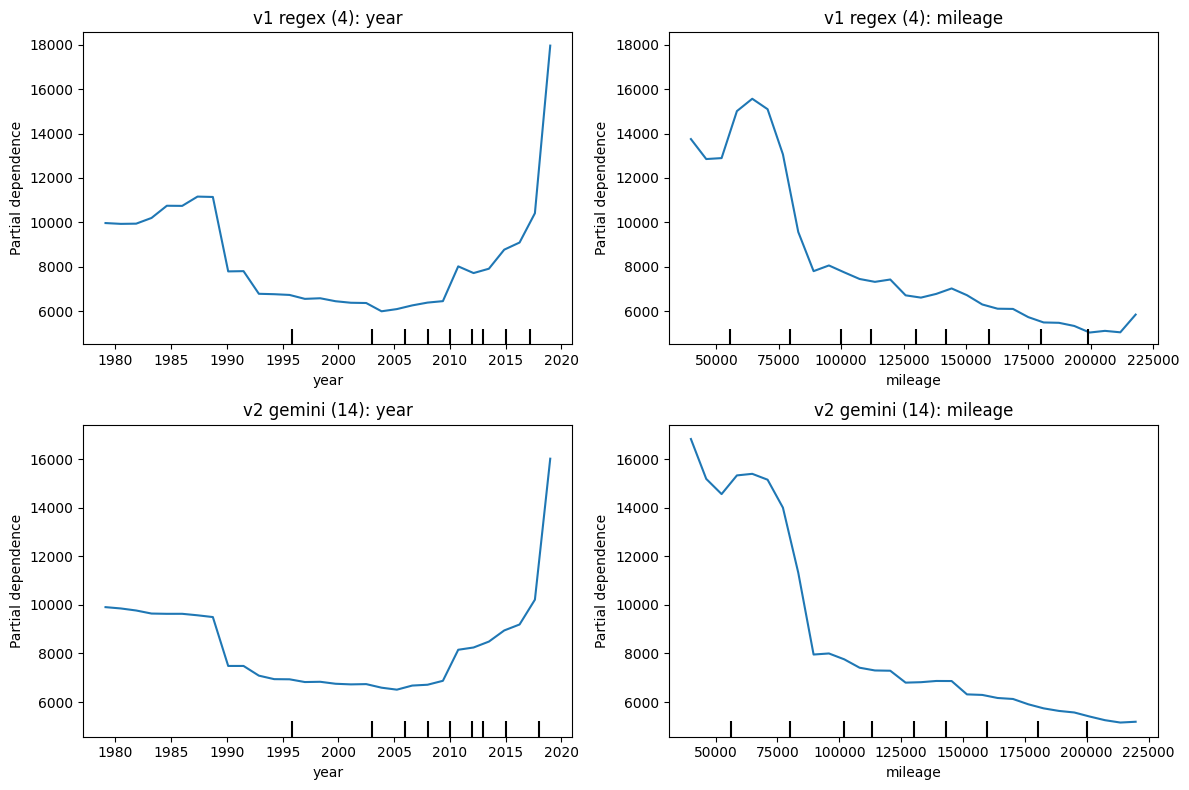

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
rows = [(V1, 0), (V2, 1)]
for version, r in rows:
    PartialDependenceDisplay.from_estimator(best[version], VERSIONS[version].loc[train_idx], ["year", "mileage"],
                                            ax=axes[r], grid_resolution=30)
    axes[r][0].set_title(version + ": year")
    axes[r][1].set_title(version + ": mileage")
plt.tight_layout()
plt.show()

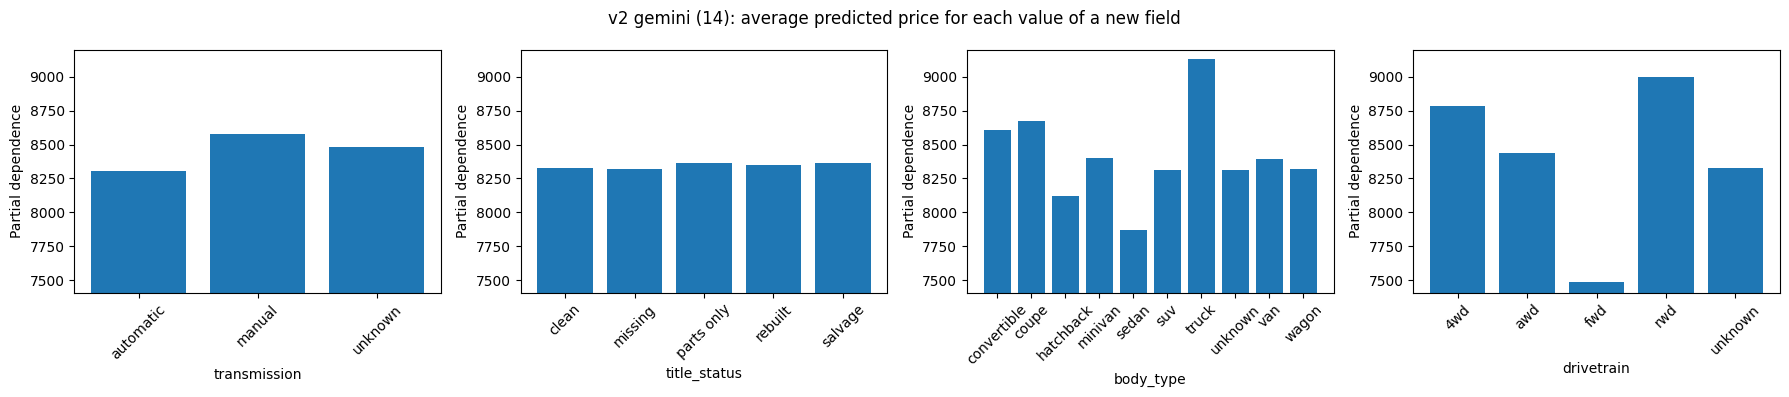

In [16]:
new_to_show = []
for col in ["transmission", "title_status", "body_type", "drivetrain"]:
    if col in NEW_FIELDS:
        new_to_show.append(col)
if len(new_to_show) == 0:
    new_to_show = NEW_FIELDS[:4]                       # your own fields

X_pd = X_v2.loc[train_idx].copy()
for col in NEW_FIELDS:
    X_pd[col] = X_pd[col].fillna("unknown")           # the model fills blanks with "unknown" too, so nothing changes

if len(new_to_show) > 0:
    fig, axes = plt.subplots(1, len(new_to_show), figsize=(4.5 * len(new_to_show), 4), squeeze=False)
    PartialDependenceDisplay.from_estimator(best[V2], X_pd, new_to_show, categorical_features=new_to_show, ax=axes[0])
    for i in range(len(new_to_show)):
        axes[0][i].tick_params(axis="x", rotation=45)
    plt.suptitle(V2 + ": average predicted price for each value of a new field")
    plt.tight_layout()
    plt.show()

## 10. The same car, scored twice
The newest cars with both predictions side by side, and what Gemini read in the ad. Where do the models disagree most,
and which one was closer? **Read a few of the ads** (`source_txt` in your bucket) to see who was right.

In [17]:
show_cols = ["day", "year_rx", "make_rx", "model_rx", "model_gm"]
for col in NEW_FIELDS[:5]:
    show_cols.append(col)
side = cars.loc[test_idx, show_cols].copy()
side["actual"] = y.loc[test_idx]
side["regex_pred"] = best[V1].predict(X_v1.loc[test_idx]).round(0)
side["gemini_pred"] = best[V2].predict(X_v2.loc[test_idx]).round(0)
side["regex_miss"] = (side["regex_pred"] - side["actual"]).abs()
side["gemini_miss"] = (side["gemini_pred"] - side["actual"]).abs()
side["gap"] = (side["regex_pred"] - side["gemini_pred"]).abs()
print("Gemini was closer on", int((side["gemini_miss"] < side["regex_miss"]).sum()), "of", len(side), "test cars")
side.sort_values("gap", ascending=False).head(10)

Gemini was closer on 46 of 87 test cars


,day,year_rx,make_rx,model_rx,model_gm,trim,body_type,drivetrain,transmission,fuel_type,actual,regex_pred,gemini_pred,regex_miss,gemini_miss,gap
427,2026-10-11,2005,scion,xa,xa,NaN,hatchback,fwd,automatic,gas,3900,17909.0,8754.0,14009.0,4854.0,9155.0
391,2026-10-08,1963,chevrolet,bel,bel air,NaN,coupe,rwd,manual,gas,37000,15328.0,23130.0,21672.0,13870.0,7802.0
412,2026-10-10,2005,toyota,prius,prius,NaN,hatchback,NaN,automatic,hybrid,1200,5692.0,12413.0,4492.0,11213.0,6721.0
431,2026-10-12,2004,jeep,wrangler,wrangler unlimited lj,unlimited lj,suv,4wd,automatic,gas,15999,11829.0,5362.0,4170.0,10637.0,6467.0
456,2026-10-13,2013,toyota,prius,prius plug-in hybrid,NaN,hatchback,fwd,automatic,hybrid,8900,10753.0,6760.0,1853.0,2140.0,3993.0
383,2026-10-08,2011,toyota,prius,prius,NaN,hatchback,fwd,automatic,hybrid,2500,4279.0,7555.0,1779.0,5055.0,3276.0
452,2026-10-13,2011,toyota,prius,prius,NaN,hatchback,fwd,automatic,hybrid,1600,4279.0,7555.0,2679.0,5955.0,3276.0
415,2026-10-10,1994,chevrolet,gmt-400,silverado,z71,truck,4wd,automatic,gas,30000,23204.0,26420.0,6796.0,3580.0,3216.0
388,2026-10-08,2016,jeep,wrangler,wrangler unlimited,sahara,suv,4wd,automatic,gas,16000,9751.0,6770.0,6249.0,9230.0,2981.0
409,2026-10-09,2013,nissan,frontier,frontier,NaN,truck,4wd,automatic,gas,7600,5438.0,8061.0,2162.0,461.0,2623.0


## 11. Would more data help?
Retrain each champion recipe on bigger and bigger slices of the cars (5-fold CV, repeated 3 times at each size) and
plot the MAE. If a curve is still falling at the right edge, that model is **still hungry**: more cars should make it
better. If the Gemini curve falls faster, the gap between the two models should **widen** as your scraper keeps running.

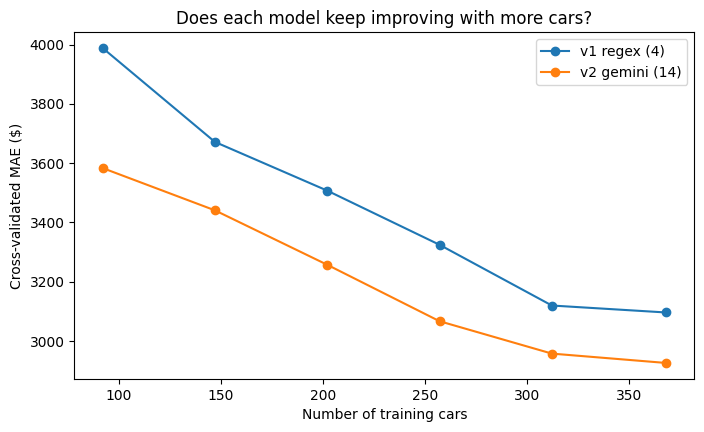

,v1 regex (4),v2 gemini (14)
training cars,,
92,3989.0,3583.0
147,3672.0,3441.0
202,3507.0,3257.0
257,3324.0,3067.0
312,3120.0,2957.0
368,3096.0,2926.0


In [18]:
from sklearn.model_selection import learning_curve

sizes = np.linspace(0.25, 1.0, 6)
curve_folds = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
fig, ax = plt.subplots(figsize=(8, 4.5))
curve_table = pd.DataFrame()
for version in [V1, V2]:
    n_train, _, val_scores = learning_curve(best[version], VERSIONS[version], y, train_sizes=sizes, cv=curve_folds,
                                            scoring="neg_mean_absolute_error", n_jobs=-1, shuffle=True,
                                            random_state=SEED)
    mae = -val_scores.mean(axis=1)
    ax.plot(n_train, mae, marker="o", label=version)
    curve_table[version] = np.round(mae)
curve_table.index = n_train
curve_table.index.name = "training cars"
ax.set_xlabel("Number of training cars")
ax.set_ylabel("Cross-validated MAE ($)")
ax.set_title("Does each model keep improving with more cars?")
ax.legend()
plt.show()
curve_table

## What you would tell your manager
Four short sections, with numbers from above:
1. **The result:** which version won, by how much (MAE in dollars), and on how many of the 25 paired folds.
2. **Why:** how much came from Gemini reading the same fields better (v1 to v1.5) vs the new fields (v1.5 to v2), and
   which new fields the importance plots say matter.
3. **The cost:** Gemini costs about \$2 per 1,000 cars and about 5 seconds per car; the regex is essentially free.
4. **The call:** which model is live now, and what you would test next.

### Dr. Wanik's memo
Read the one-page memo written from the numbers above: [DrWanik_Bakeoff_Memo.pdf](https://github.com/drdave-teaching/OPIM5512-labs/blob/master/Module3/A08_Midterm/handouts/DrWanik_Bakeoff_Memo.pdf).
Yours follows the same four sections, with your cars and your fields.